# 32 — GeoMAE vs NodeGRU Diagnostics + Spatial/Wind Error Analysis
## Paired Emerging-3 evaluation, complementary cases, and wind diagnostics — **no retraining**

**Purpose (follow-up to executed NB31B).** The NB31B August development result favored `GeoMAE-ST` among GeoMAE variants, while `NodeGRU-L14` remained slightly higher on Emerging-3. Explicit wind features did not improve August Emerging PR-AUC. This notebook investigates **where** those differences arise, without changing, tuning, or rerunning any model.

### What this notebook does

1. Load the **exact August per-cell predictions** exported by NB31B (`all_model_august_predictions.csv`).
2. Recompute matched Overall, Emerging-3, and Persistent PR-AUC.
3. Estimate **paired date-block bootstrap confidence intervals**, in particular `GeoMAE-ST − NodeGRU-L14` and `GeoMAE-ST-Wind − GeoMAE-ST`.
4. Compare **daily operational top-K detection**, matched across the same Emerging-eligible cells.
5. Identify **GeoMAE-only** and **NodeGRU-only** correctly ranked Emerging-positive examples. Cases are illustrations, not unbiased performance estimates.
6. Reconstruct **nearby hotspot / wind-aligned source exposure using data available by day t**, and compare the effects of enabling wind on model scores.
7. Produce clean **0.25° three-model grid maps** and a plain-text supervision summary.

### Interpretation safeguards

- The August set has been used repeatedly during development. This is a **post-development diagnostic**, not an untouched final test.
- No trained model is changed. Do not claim that wind caused the observed performance difference.
- A FIRMS-positive grid means an **observed satellite hotspot detection**; it is not ignition-cause ground truth.
- The NB31B `GeoMAE-T/ST/ST-Wind` variants share an NB24 pretraining checkpoint. Feature hiding at downstream training is useful, but **not** the same as independently pretraining each masked-input variant.
- The primary chart here is descriptive performance on **Emerging-3 eligible** center cell-days, not confirmed natural vs anthropogenic fires.

In [2]:
# 1. Imports
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)
SEED = 20261017
BOOTSTRAPS = 3000  # paired date-block resamples (same sampled dates for both models)
TOP_K = [5, 10, 20]
MAP_DATE = pd.Timestamp("2026-08-02")  # fixed upfront to match your existing August 2 maps
CELL_SIZE_DEG = 0.25
print("No neural training or model selection is performed in NB32.")

No neural training or model selection is performed in NB32.


In [3]:
# 2. Locate NB31B exports and regional dataset
cwd = Path.cwd()
roots = [cwd, cwd.parent, cwd.parent.parent,
         Path("/content/skripsi-karhut"), Path("/content/drive/MyDrive/skripsi-karhut")]
PROJECT_ROOT = None
for root in roots:
    if (root / "model_results" / "geomae_controlled_ablation" / "t2" / "exports" /
        "all_model_august_predictions.csv").exists():
        PROJECT_ROOT = root
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "NB31B's model_results/geomae_controlled_ablation/t2/exports/"
        "all_model_august_predictions.csv was not found. "
        "Run NB31B export cell #25, then run NB32 from the project notebooks folder."
    )
SOURCE_DIR = PROJECT_ROOT / "model_results" / "geomae_controlled_ablation" / "t2" / "exports"
REGIONAL_PATH = PROJECT_ROOT / "data" / "processed" / "regional_025" / "karhut_ml_dataset_regional_025.csv"
RESULT_DIR = PROJECT_ROOT / "model_results" / "geomae_nb32_diagnostics" / "t2"
EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
for p in [SOURCE_DIR / "all_model_august_predictions.csv", REGIONAL_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Required source missing: {p}")
print("PROJECT_ROOT:", PROJECT_ROOT)
print("NB31B EXPORTS:", SOURCE_DIR)
print("NB32 OUTPUT  :", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
NB31B EXPORTS: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_controlled_ablation\t2\exports
NB32 OUTPUT  : c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_nb32_diagnostics\t2


In [4]:
# 3. Load and audit exact NB31B exported predictions
raw = pd.read_csv(SOURCE_DIR / "all_model_august_predictions.csv", parse_dates=["date"])
raw["cell_id"] = raw["cell_id"].astype(str)
required = {
    "date", "cell_id", "target_fire_active_t1", "active_days_prev3_incl_t",
    "GeoMAE-T", "GeoMAE-ST", "GeoMAE-ST-Wind",
    "Transformer-ST-Wind Scratch", "LR13 baseline (matched train)", "nodegru_score"
}
missing = sorted(required - set(raw.columns))
if missing:
    raise ValueError(f"Required columns missing from NB31B CSV: {missing}")
assert not raw.duplicated(["date", "cell_id"]).any(), "Duplicate cell-days"
assert raw["date"].between("2026-08-01", "2026-08-31").all(), "This must be August only"
MODEL_COLS = {
    "GeoMAE-T": "GeoMAE-T",
    "GeoMAE-ST": "GeoMAE-ST",
    "GeoMAE-ST-Wind": "GeoMAE-ST-Wind",
    "Transformer-ST-Wind Scratch": "Transformer-ST-Wind Scratch",
    "LR13 baseline": "LR13 baseline (matched train)",
    "NodeGRU-L14 baseline": "nodegru_score",
}
for model_col in MODEL_COLS.values():
    if not np.isfinite(pd.to_numeric(raw[model_col], errors="coerce")).all():
        raise ValueError(f"Nonfinite prediction scores for {model_col}")
assert raw["target_fire_active_t1"].dropna().isin([0,1]).all()
work = raw.sort_values(["date","cell_id"]).reset_index(drop=True).copy()
work["y"] = work["target_fire_active_t1"].astype(int)
work["emerging_eligible"] = work["active_days_prev3_incl_t"].eq(0)
work["emerging_positive"] = work["emerging_eligible"] & work["y"].eq(1)
work["persistent_context"] = ~work["emerging_eligible"]
assert work["date"].nunique() == 31, "Expected all 31 August dates"
print("August cell-days:",len(work), "| Grid cells:",work["cell_id"].nunique())
print("Emerging eligible:",int(work["emerging_eligible"].sum()),
      "| Emerging positives:",int(work["emerging_positive"].sum()))
print("NB31B comparator columns checked:",len(MODEL_COLS))

August cell-days: 4123 | Grid cells: 133
Emerging eligible: 1241 | Emerging positives: 224
NB31B comparator columns checked: 6


In [5]:
# 4. Recompute the matched leaderboard, without changing any score

def ap_safe(y, score):
    y=np.asarray(y,dtype=int); score=np.asarray(score,dtype=float)
    return float(average_precision_score(y,score)) if y.sum()>0 else np.nan

def auc_safe(y, score):
    y=np.asarray(y,dtype=int); score=np.asarray(score,dtype=float)
    return float(roc_auc_score(y,score)) if np.unique(y).size==2 else np.nan

rows=[]
for name,col in MODEL_COLS.items():
    for subset_name, mask in [
        ("Overall",np.ones(len(work),dtype=bool)),
        ("Emerging-3 eligible",work["emerging_eligible"].to_numpy()),
        ("Persistent-context",work["persistent_context"].to_numpy()),
    ]:
        subset=work.loc[mask]
        rows.append({"Model":name,"Subset":subset_name,"Rows":len(subset),
            "Positives":int(subset["y"].sum()),"Prevalence":float(subset["y"].mean()),
            "PR-AUC":ap_safe(subset["y"],subset[col]),
            "ROC-AUC":auc_safe(subset["y"],subset[col])})
leaderboard=pd.DataFrame(rows)
emerging_table=(leaderboard[leaderboard["Subset"].eq("Emerging-3 eligible")]
    .sort_values("PR-AUC",ascending=False))
print("=== AUGUST EMERGING-3 PR-AUC (post-development descriptive) ===")
display(emerging_table)
print("=== OVERALL AND PERSISTENT ===")
display(leaderboard.pivot(index="Model",columns="Subset",values="PR-AUC"))

=== AUGUST EMERGING-3 PR-AUC (post-development descriptive) ===


,Model,Subset,Rows,Positives,Prevalence,PR-AUC,ROC-AUC
16,NodeGRU-L14 baseline,Emerging-3 eligible,1241,224,0.1805,0.337232,0.703059
4,GeoMAE-ST,Emerging-3 eligible,1241,224,0.1805,0.322046,0.639354
1,GeoMAE-T,Emerging-3 eligible,1241,224,0.1805,0.288550,0.619991
7,GeoMAE-ST-Wind,Emerging-3 eligible,1241,224,0.1805,0.285513,0.633643
13,LR13 baseline,Emerging-3 eligible,1241,224,0.1805,0.276978,0.649031
10,Transformer-ST-Wind Scratch,Emerging-3 eligible,1241,224,0.1805,0.252851,0.596116


=== OVERALL AND PERSISTENT ===


Subset,Emerging-3 eligible,Overall,Persistent-context
Model,,,
GeoMAE-ST,0.322046,0.822513,0.906221
GeoMAE-ST-Wind,0.285513,0.766745,0.892775
GeoMAE-T,0.288550,0.836359,0.908297
LR13 baseline,0.276978,0.877614,0.909170
NodeGRU-L14 baseline,0.337232,0.866500,0.893491
Transformer-ST-Wind Scratch,0.252851,0.823387,0.906654


## Paired date-block bootstrap

For each comparison, resample **entire dates with replacement**. This preserves same-day spatial correlation better than treating grid-cell observations as independent. Recalculate both PR-AUC values on the **same sampled dates** and take their difference.

Important: The 95% intervals quantify sampling variability conditional on the fitted scores, not architecture/seed/pretraining uncertainty. They do **not** make August an untouched test set.

In [6]:
# 5. Paired date-block PR-AUC differences and 95% intervals
PAIRS = [
    ("GeoMAE-ST vs NodeGRU-L14", "NodeGRU-L14 baseline", "GeoMAE-ST"),
    ("GeoMAE-ST vs LR13", "LR13 baseline", "GeoMAE-ST"),
    ("Spatial effect: GeoMAE-ST vs T", "GeoMAE-T", "GeoMAE-ST"),
    ("Wind effect: ST-Wind vs ST", "GeoMAE-ST", "GeoMAE-ST-Wind"),
    ("Pretraining: GeoMAE-ST-Wind vs Scratch", "Transformer-ST-Wind Scratch", "GeoMAE-ST-Wind"),
]
rng=np.random.default_rng(SEED)
days=np.array(sorted(work["date"].unique()))
day_indices=[np.flatnonzero(work["date"].eq(d).to_numpy()) for d in days]
sampled_index_blocks=[np.concatenate([day_indices[j] for j in rng.integers(len(days),size=len(days))])
                      for _ in range(BOOTSTRAPS)]
mask_eligible=work["emerging_eligible"].to_numpy()
y=work["y"].to_numpy()
paired_rows=[]
for label, left_name, right_name in PAIRS:
    left=work[MODEL_COLS[left_name]].to_numpy()
    right=work[MODEL_COLS[right_name]].to_numpy()
    raw_idx=np.flatnonzero(mask_eligible)
    obs=ap_safe(y[raw_idx],right[raw_idx])-ap_safe(y[raw_idx],left[raw_idx])
    diffs=[]
    for block in sampled_index_blocks:
        ix=block[mask_eligible[block]]
        if y[ix].sum()==0 or y[ix].sum()==len(ix):
            continue
        diffs.append(ap_safe(y[ix],right[ix])-ap_safe(y[ix],left[ix]))
    lo,hi=np.quantile(diffs,[0.025,0.975]) if diffs else (np.nan,np.nan)
    paired_rows.append({"Comparison":label,"Emerging PR-AUC Δ (right - left)":obs,
        "95% CI lower":lo,"95% CI upper":hi,"Valid replicates":len(diffs),
        "CI entirely positive":bool(lo>0) if np.isfinite(lo) else False,
        "CI entirely negative":bool(hi<0) if np.isfinite(hi) else False})
paired_ci=pd.DataFrame(paired_rows)
display(paired_ci)

,Comparison,Emerging PR-AUC Δ (right - left),95% CI lower,95% CI upper,Valid replicates,CI entirely positive,CI entirely negative
0,GeoMAE-ST vs NodeGRU-L14,-0.015186,-0.071737,0.046286,3000,False,False
1,GeoMAE-ST vs LR13,0.045068,-0.004929,0.098022,3000,False,False
2,Spatial effect: GeoMAE-ST vs T,0.033496,-0.008418,0.087378,3000,False,False
3,Wind effect: ST-Wind vs ST,-0.036533,-0.077990,-0.003226,3000,False,True
4,Pretraining: GeoMAE-ST-Wind vs Scratch,0.032662,-0.013996,0.089511,3000,False,False


Days with ≥1 Emerging positive: 30


,Model,days_with_positives,mean_daily_pr
0,GeoMAE-ST,30,0.421517
1,GeoMAE-ST-Wind,30,0.361524
2,GeoMAE-T,30,0.373019
3,LR13 baseline,30,0.376536
4,NodeGRU-L14 baseline,30,0.435823
5,Transformer-ST-Wind Scratch,30,0.348243


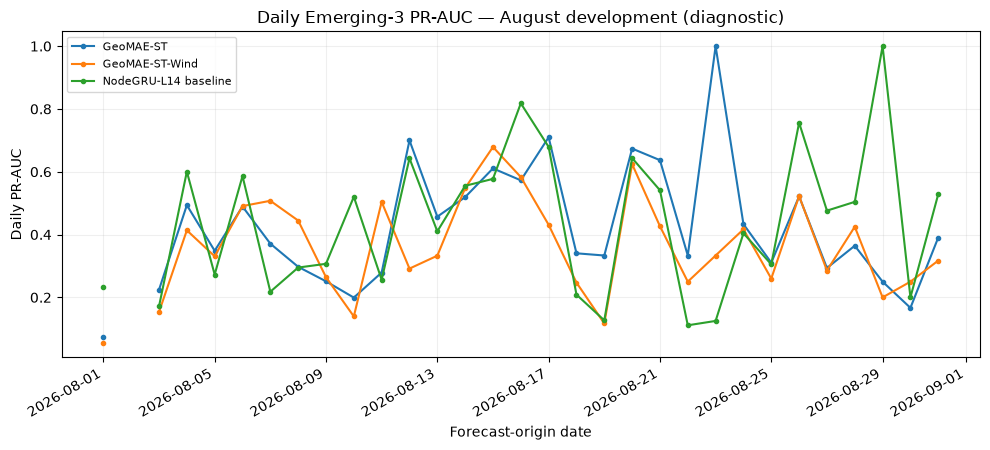

In [7]:
# 6. Daily Emerging-3 PR-AUC (descriptive: small per-day counts are unstable)
daily_rows=[]
for date,day in work[work["emerging_eligible"]].groupby("date"):
    pos=int(day["y"].sum())
    for name,col in MODEL_COLS.items():
        daily_rows.append({"date":date,"Model":name,
            "Eligible cells":len(day),"Emerging positives":pos,
            "Daily PR-AUC":ap_safe(day["y"],day[col])})
daily=pd.DataFrame(daily_rows)
select_models=["GeoMAE-ST","GeoMAE-ST-Wind","NodeGRU-L14 baseline"]
pivot=daily[daily["Model"].isin(select_models)].pivot(
    index="date",columns="Model",values="Daily PR-AUC")
print("Days with ≥1 Emerging positive:",daily[daily["Model"].eq("GeoMAE-ST")]["Daily PR-AUC"].notna().sum())
display(daily.groupby("Model",as_index=False).agg(
    days_with_positives=("Daily PR-AUC",lambda x:int(x.notna().sum())),
    mean_daily_pr=("Daily PR-AUC","mean")))
fig,ax=plt.subplots(figsize=(10,4.6))
for name in select_models:
    ax.plot(pivot.index,pivot[name],marker="o",ms=3,label=name)
ax.set(title="Daily Emerging-3 PR-AUC — August development (diagnostic)",ylabel="Daily PR-AUC",xlabel="Forecast-origin date")
ax.legend(fontsize=8); ax.grid(alpha=.2);fig.autofmt_xdate();fig.tight_layout()
fig.savefig(FIGURE_DIR/"01_daily_emerging_pr.png",dpi=180,bbox_inches="tight")
plt.show()

## Operational comparison: Recall@K among Emerging-eligible cells

At the end of day `t`, restrict the candidate set to cells with no local detections during the relevant preceding window; then rank them by each model's next-day score. For each date, a hypothetical review team can inspect at most `K` cells. The denominator for the **pooled Recall@K** is the total number of actual Emerging positives across dates. Ties are broken deterministically by `cell_id` for all models; no model is given a different budget.

In [8]:
# 7. Per-day ranking within Emerging-3 eligible cells + matched Top-K
elig=work[work["emerging_eligible"]].copy()
rank_cols={}
for name,col in MODEL_COLS.items():
    key=f"rank__{name}"
    # Deterministic within-date ranking; ties get the same cell_id secondary sort
    sort_df=elig[["date","cell_id",col]].sort_values(
        ["date",col,"cell_id"],ascending=[True,False,True],kind="mergesort")
    sort_df[key]=sort_df.groupby("date").cumcount()+1
    elig=elig.merge(sort_df[["date","cell_id",key]],on=["date","cell_id"],validate="one_to_one")
    rank_cols[name]=key

budget_rows=[]
for k in TOP_K:
    for name,rcol in rank_cols.items():
        chosen=elig[rcol].le(k)
        budget_rows.append({"K cells/day":k,"Model":name,"Captured Emerging events":int(elig.loc[chosen,"y"].sum()),
            "All Emerging events":int(elig["y"].sum()),
            "Pooled Recall@K":float(elig.loc[chosen,"y"].sum()/max(1,elig["y"].sum())),
            "Mean cells inspected/day":float(chosen.sum()/elig["date"].nunique())})
budget_table=pd.DataFrame(budget_rows)
display(budget_table[budget_table["Model"].isin(select_models)].sort_values(["K cells/day","Pooled Recall@K"],ascending=[True,False]))

,K cells/day,Model,Captured Emerging events,All Emerging events,Pooled Recall@K,Mean cells inspected/day
1,5,GeoMAE-ST,57,224,0.254464,5.000000
5,5,NodeGRU-L14 baseline,56,224,0.250000,5.000000
2,5,GeoMAE-ST-Wind,50,224,0.223214,5.000000
11,10,NodeGRU-L14 baseline,96,224,0.428571,10.000000
7,10,GeoMAE-ST,92,224,0.410714,10.000000
8,10,GeoMAE-ST-Wind,75,224,0.334821,10.000000
17,20,NodeGRU-L14 baseline,147,224,0.656250,19.677419
13,20,GeoMAE-ST,137,224,0.611607,19.677419
14,20,GeoMAE-ST-Wind,133,224,0.593750,19.677419


In [9]:
# 8. Find complementary positive cases, without treating chosen cases as aggregate evidence
CASE_K=10
positive=elig[elig["y"].eq(1)].copy()
rank_st=rank_cols["GeoMAE-ST"]
rank_gru=rank_cols["NodeGRU-L14 baseline"]
positive["ST_top10"]=positive[rank_st].le(CASE_K)
positive["GRU_top10"]=positive[rank_gru].le(CASE_K)
positive["case_type"]=np.select([
    positive["ST_top10"] & ~positive["GRU_top10"],
    ~positive["ST_top10"] & positive["GRU_top10"],
    positive["ST_top10"] & positive["GRU_top10"]],
    ["GeoMAE-ST only","NodeGRU only","Both"],default="Neither")
positive["rank_gap_ST_minus_GRU"]=positive[rank_st]-positive[rank_gru]
composition=positive["case_type"].value_counts().rename_axis("Outcome").reset_index(name="Emerging-positive count")
display(composition)
case_cols=["date","cell_id","case_type",rank_st,rank_gru,
           "GeoMAE-ST","GeoMAE-ST-Wind","nodegru_score","rank_gap_ST_minus_GRU"]
case_examples=pd.concat([
    positive[positive["case_type"].eq("GeoMAE-ST only")].sort_values("rank_gap_ST_minus_GRU").head(6),
    positive[positive["case_type"].eq("NodeGRU only")].sort_values("rank_gap_ST_minus_GRU",ascending=False).head(6),
    positive[positive["case_type"].eq("Both")].sort_values("date").head(3),
],ignore_index=True)
print("Top-K is operational illustration; do not use selected cases as unbiased accuracy proof.")
display(case_examples[case_cols])

,Outcome,Emerging-positive count
0,Neither,99
1,Both,63
2,NodeGRU only,33
3,GeoMAE-ST only,29


Top-K is operational illustration; do not use selected cases as unbiased accuracy proof.


,date,cell_id,case_type,rank__GeoMAE-ST,rank__NodeGRU-L14 baseline,GeoMAE-ST,GeoMAE-ST-Wind,nodegru_score,rank_gap_ST_minus_GRU
0,2026-08-08,regional025_9_25,GeoMAE-ST only,7,44,0.845745,0.827804,0.209936,-37
1,2026-08-07,regional025_9_22,GeoMAE-ST only,3,40,0.859418,0.814905,0.209936,-37
2,2026-08-16,regional025_7_25,GeoMAE-ST only,6,38,0.846512,0.806809,0.209936,-32
3,2026-08-07,regional025_8_25,GeoMAE-ST only,7,38,0.828205,0.890494,0.209936,-31
4,2026-08-11,regional025_8_26,GeoMAE-ST only,9,35,0.784458,0.790330,0.209936,-26
5,2026-08-15,regional025_4_24,GeoMAE-ST only,6,29,0.872786,0.829383,0.393609,-23
6,2026-08-01,regional025_13_22,NodeGRU only,52,4,0.536119,0.543596,0.767375,48
7,2026-08-14,regional025_12_28,NodeGRU only,49,8,0.601200,0.711954,0.849443,41
8,2026-08-04,regional025_11_25,NodeGRU only,47,9,0.724069,0.797465,0.799753,38
9,2026-08-06,regional025_10_27,NodeGRU only,43,9,0.663255,0.803377,0.619121,34


## Wind-alignment diagnostics (existing wind data, **no model rerun**)

Reconstruct only **observational features known by origin day `t`** at each Emerging-eligible cell-day. For every nearby cell in its 3×3 neighborhood and lags `t, t−1, t−2`, compute:

- nearby hotspot exposure with distance decay;
- positive alignment of **source-cell wind vector** toward the candidate cell, weighted by nearby hotspot activity.

This helps diagnose **whether the wind variant changes its scores more for some spatial contexts**, and whether that shift differs between actual next-day hotspot positives and negatives. It does **not** prove the wind features caused better/worse predictions, or that flames followed the daily-mean wind. ERA5 wind is not point-level fire-spread ground truth.

In [10]:
# 9. Build wind-aware neighbor exposure features for August Emerging-eligible rows
regional=pd.read_csv(REGIONAL_PATH,parse_dates=["date"])
regional["cell_id"]=regional["cell_id"].astype(str)
need={"date","grid_lat","grid_lon","fire_active","fire_count","frp_sum","wind_u_mean","wind_v_mean","cell_id"}
if not need.issubset(regional.columns):
    raise ValueError(f"Missing regional columns: {sorted(need-set(regional.columns))}")
coord=regional[["cell_id","grid_lat","grid_lon"]].drop_duplicates("cell_id")
assert not coord["cell_id"].duplicated().any()
elig=elig.merge(coord,on="cell_id",how="left",validate="many_to_one")
assert elig[["grid_lat","grid_lon"]].notna().all().all(),"Some cells have no coords"
regional["lat_key"]=regional["grid_lat"].round(3)
regional["lon_key"]=regional["grid_lon"].round(3)
assert not regional.duplicated(["date","lat_key","lon_key"]).any()

# Vectorized source-to-target join for eight neighbors on each of three dates.
parts=[]
for lag in [0,1,2]:
    for dx in [-1,0,1]:
        for dy in [-1,0,1]:
            if dx==0 and dy==0:
                continue
            tmp=elig[["date","cell_id","grid_lat","grid_lon"]].copy()
            tmp["lag"]=lag; tmp["dx"]=dx; tmp["dy"]=dy
            tmp["source_date"]=tmp["date"]-pd.Timedelta(days=lag)
            tmp["lat_key"]=(tmp["grid_lat"]+dy*CELL_SIZE_DEG).round(3)
            tmp["lon_key"]=(tmp["grid_lon"]+dx*CELL_SIZE_DEG).round(3)
            parts.append(tmp)
neighbor_req=pd.concat(parts,ignore_index=True)
source_cols=["date","lat_key","lon_key","fire_active","fire_count","frp_sum","wind_u_mean","wind_v_mean"]
neighbor_req=neighbor_req.merge(regional[source_cols].rename(columns={
    "date":"source_date","fire_active":"source_fire_active", "fire_count":"source_fire_count",
    "frp_sum":"source_frp_sum", "wind_u_mean":"source_u", "wind_v_mean":"source_v"}),
    on=["source_date","lat_key","lon_key"],how="left",validate="many_to_one")

# Approximate local direction from source to target, respecting longitude at latitude.
lat_src=neighbor_req["lat_key"].to_numpy(dtype=float)
lon_src=neighbor_req["lon_key"].to_numpy(dtype=float)
lat_target=neighbor_req["grid_lat"].to_numpy(dtype=float)
lon_target=neighbor_req["grid_lon"].to_numpy(dtype=float)
meanlat=np.radians((lat_src+lat_target)/2)
east=(lon_target-lon_src)*111.320*np.cos(meanlat)
north=(lat_target-lat_src)*110.574
dist=np.hypot(east,north)
u=neighbor_req["source_u"].fillna(0).to_numpy(dtype=float)
v=neighbor_req["source_v"].fillna(0).to_numpy(dtype=float)
speed=np.hypot(u,v)
cosine=(u*east+v*north)/np.maximum(speed*dist,1e-9)
aligned=np.where(speed>=0.5,np.clip(cosine,0,1),0.)
active=neighbor_req["source_fire_active"].fillna(0).to_numpy(dtype=float)
dist_weight=np.exp(-dist/50.0)
neighbor_req["nearby_active_exposure"]=active*dist_weight
neighbor_req["aligned_active_exposure"]=active*dist_weight*aligned
neighbor_req["aligned_count_exposure"]=np.log1p(neighbor_req["source_fire_count"].fillna(0).clip(lower=0))*dist_weight*aligned
neighbor_req["aligned_frp_exposure"]=np.log1p(neighbor_req["source_frp_sum"].fillna(0).clip(lower=0))*dist_weight*aligned
summary=(neighbor_req.groupby(["date","cell_id"],as_index=False)
         .agg(nearby_active_exposure=("nearby_active_exposure","sum"),
              aligned_active_exposure=("aligned_active_exposure","sum"),
              aligned_count_exposure=("aligned_count_exposure","sum"),
              aligned_frp_exposure=("aligned_frp_exposure","sum")))
assert len(summary)==len(elig)
elig=elig.merge(summary,on=["date","cell_id"],how="left",validate="one_to_one")
elig["wind_score_shift"]=(elig["GeoMAE-ST-Wind"]-elig["GeoMAE-ST"])
elig["has_near_hotspot"]=elig["nearby_active_exposure"].gt(0)
elig["has_wind_aligned_hotspot"]=elig["aligned_active_exposure"].gt(0)
print("Emerging-eligible cells with any nearby hotspot:",int(elig["has_near_hotspot"].sum()))
print("Emerging-eligible cells with wind-aligned nearby hotspot:",int(elig["has_wind_aligned_hotspot"].sum()))
display(elig[["date","cell_id","y","nearby_active_exposure","aligned_active_exposure","wind_score_shift"]].head())

Emerging-eligible cells with any nearby hotspot: 1214
Emerging-eligible cells with wind-aligned nearby hotspot: 1113


,date,cell_id,y,nearby_active_exposure,aligned_active_exposure,wind_score_shift
0,2026-08-01,regional025_10_22,0,1.369348,1.328496,-0.254874
1,2026-08-01,regional025_10_23,0,1.725889,1.461902,-0.175892
2,2026-08-01,regional025_10_24,0,1.942673,0.718932,-0.140103
3,2026-08-01,regional025_10_26,0,1.603100,0.950106,-0.010024
4,2026-08-01,regional025_10_29,0,4.123015,2.062972,0.000372


,Context,Actual hotspot t+1,Rows,Mean GeoMAE-ST score,Mean GeoMAE-ST-Wind score,Mean wind-induced score change,Median wind-induced score change
0,No nearby active hotspot,0,22,0.617528,0.653318,0.035790,0.042442
1,No nearby active hotspot,1,5,0.674178,0.715512,0.041334,0.011522
2,"Nearby hotspot, not wind-aligned",0,86,0.644493,0.666823,0.022330,0.018833
3,"Nearby hotspot, not wind-aligned",1,15,0.756363,0.762185,0.005822,0.006954
4,"Nearby hotspot, wind-aligned",0,909,0.720821,0.734433,0.013612,0.020730
5,"Nearby hotspot, wind-aligned",1,204,0.772464,0.788927,0.016463,0.019296


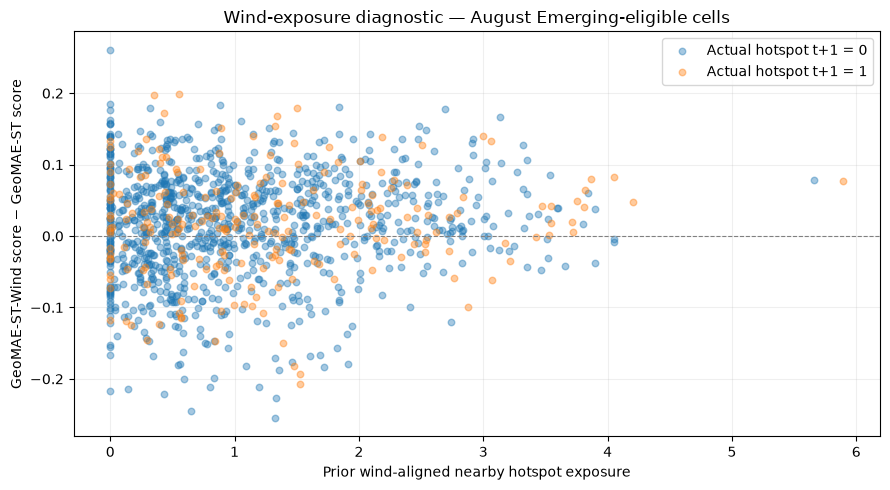

In [11]:
# 10. What happens to scores when wind context is added?
context_rows=[]
for context_name,mask in [
    ("No nearby active hotspot",~elig["has_near_hotspot"]),
    ("Nearby hotspot, not wind-aligned",elig["has_near_hotspot"] & ~elig["has_wind_aligned_hotspot"]),
    ("Nearby hotspot, wind-aligned",elig["has_wind_aligned_hotspot"]),
]:
    grp=elig[mask]
    for outcome in [0,1]:
        sub=grp[grp["y"].eq(outcome)]
        context_rows.append({"Context":context_name,"Actual hotspot t+1":outcome,
            "Rows":len(sub),"Mean GeoMAE-ST score":sub["GeoMAE-ST"].mean(),
            "Mean GeoMAE-ST-Wind score":sub["GeoMAE-ST-Wind"].mean(),
            "Mean wind-induced score change":sub["wind_score_shift"].mean(),
            "Median wind-induced score change":sub["wind_score_shift"].median()})
wind_context_table=pd.DataFrame(context_rows)
display(wind_context_table)

fig,ax=plt.subplots(figsize=(9,5))
for actual,grp in elig.groupby("y"):
    ax.scatter(grp["aligned_active_exposure"],grp["wind_score_shift"],
               s=22,alpha=.4,label=f"Actual hotspot t+1 = {actual}")
ax.axhline(0,color="0.5",linestyle="--",linewidth=.8)
ax.set(xlabel="Prior wind-aligned nearby hotspot exposure",ylabel="GeoMAE-ST-Wind score − GeoMAE-ST score",
       title="Wind-exposure diagnostic — August Emerging-eligible cells")
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(FIGURE_DIR/"02_wind_score_shift.png",dpi=180,bbox_inches="tight")
plt.show()

## Grid-aligned visualization

To preserve consistency with NB28, all panels draw the **same retained 0.25° grid cells** and use the same longitude/latitude extent and score scale. The marker indicates **observed next-day positive cells**, and a star indicates **observed Emerging-3 positives**. Scores are not calibrated probabilities. This panel **does not draw raw FIRMS point detections**, only grid-level labels, because NB31B exports are grid-based.

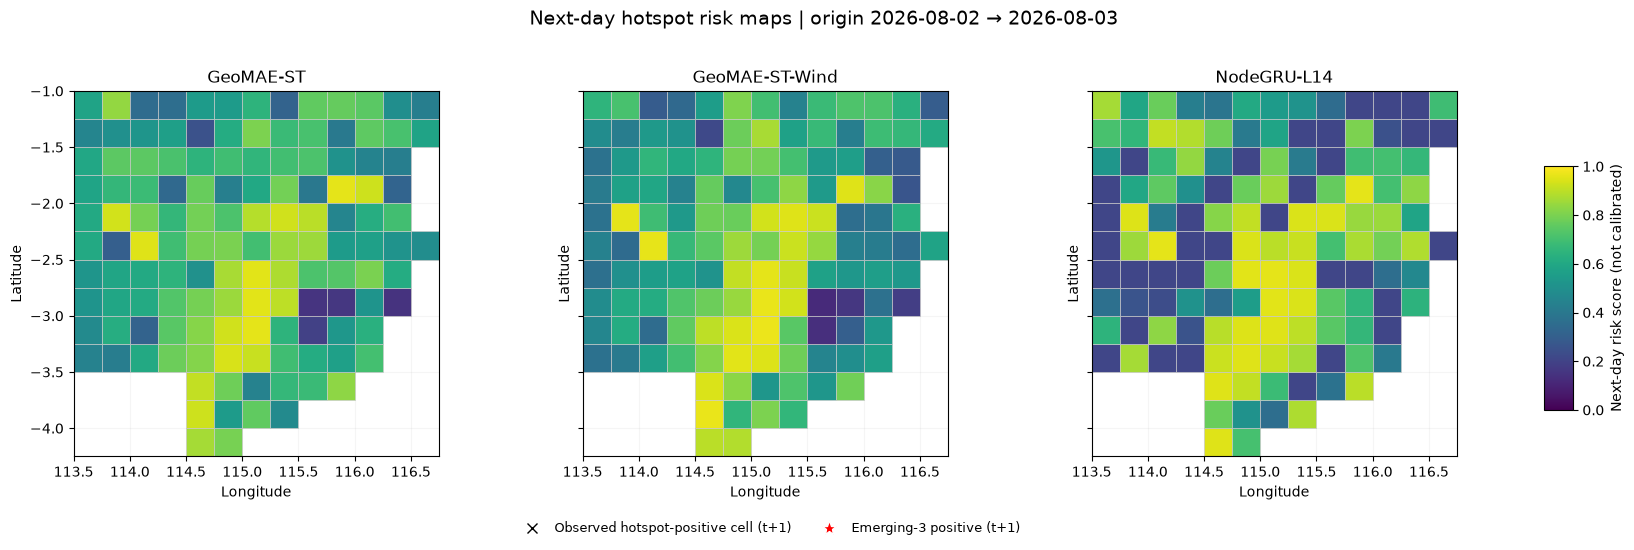

Saved c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_nb32_diagnostics\t2\figures\03_grid_three_models_origin_2026-08-02.png


In [12]:
# 11. Three aligned grid maps: GeoMAE-ST, GeoMAE-ST-Wind, NodeGRU on fixed 2026-08-02 origin
geo=work[work["date"].eq(MAP_DATE)].merge(coord,on="cell_id",how="left",validate="one_to_one")
if geo.empty:
    raise ValueError("Map origin 2026-08-02 not present in NB31B CSV")
fig,axes=plt.subplots(1,3,figsize=(18,5.8),sharex=True,sharey=True)
fig.subplots_adjust(left=.055,right=.88,top=.84,bottom=.21,wspace=.09)
norm=Normalize(vmin=0,vmax=1)
cmap=plt.get_cmap("viridis")
map_specs=[("GeoMAE-ST","GeoMAE-ST"),
           ("GeoMAE-ST-Wind","GeoMAE-ST-Wind"),
           ("NodeGRU-L14","nodegru_score")]
for ax,(title,scorecol) in zip(axes,map_specs):
    rects=[Rectangle((row.grid_lon-CELL_SIZE_DEG/2,row.grid_lat-CELL_SIZE_DEG/2),
           CELL_SIZE_DEG,CELL_SIZE_DEG) for row in geo.itertuples(index=False)]
    collection=PatchCollection(rects,cmap=cmap,norm=norm,edgecolor="0.80",linewidth=.45)
    collection.set_array(geo[scorecol].to_numpy(dtype=float));ax.add_collection(collection)
    actual=geo[geo["y"].eq(1)]
    emerging_actual=actual[actual["active_days_prev3_incl_t"].eq(0)]
    ax.scatter(actual["grid_lon"],actual["grid_lat"],marker="x",s=38,c="white",linewidths=1.2,zorder=5)
    ax.scatter(emerging_actual["grid_lon"],emerging_actual["grid_lat"],marker="*",s=130,c="red",edgecolors="white",linewidths=.5,zorder=6)
    ax.set_title(title,fontsize=12)
    ax.set_xlabel("Longitude");ax.set_ylabel("Latitude")
    ax.set_aspect("equal",adjustable="box");ax.grid(alpha=.12)
    ax.set_xlim(geo["grid_lon"].min()-.125,geo["grid_lon"].max()+.125)
    ax.set_ylim(geo["grid_lat"].min()-.125,geo["grid_lat"].max()+.125)
from matplotlib.cm import ScalarMappable
cax=fig.add_axes([.90,.29,.016,.42]); sm=ScalarMappable(norm=norm,cmap=cmap)
fig.colorbar(sm,cax=cax,label="Next-day risk score (not calibrated)")
handles=[Line2D([0],[0],marker="x",color="white",markeredgecolor="black",linestyle="none",markersize=7,label="Observed hotspot-positive cell (t+1)"),
         Line2D([0],[0],marker="*",color="red",markeredgecolor="white",linestyle="none",markersize=11,label="Emerging-3 positive (t+1)")]
fig.legend(handles=handles,loc="lower center",bbox_to_anchor=(.47,.055),ncol=2,fontsize=9,frameon=False)
fig.suptitle(f"Next-day hotspot risk maps | origin {MAP_DATE.date()} → {(MAP_DATE+pd.Timedelta(days=1)).date()}",fontsize=14)
path=FIGURE_DIR/f"03_grid_three_models_origin_{MAP_DATE.date()}.png"
fig.savefig(path,dpi=200,bbox_inches="tight")
plt.show();print("Saved",path)

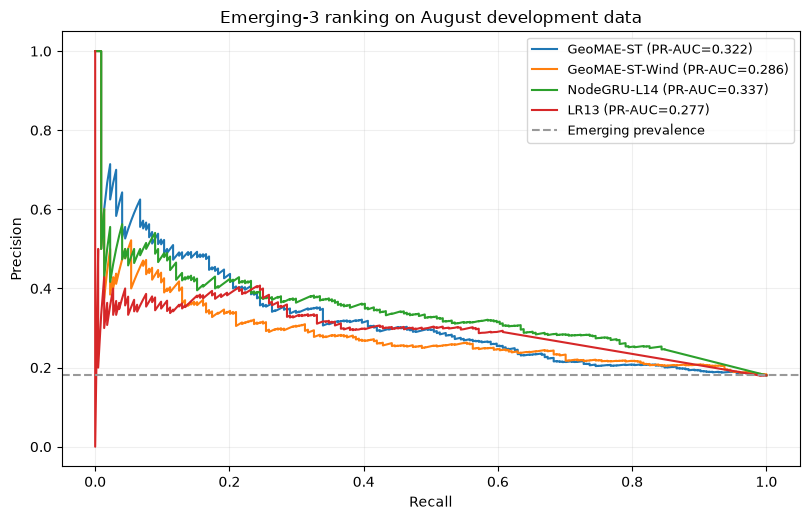

In [13]:
# 12. PR curves for all 3 leading models on identical Emerging-eligible August rows
fig,ax=plt.subplots(figsize=(8.2,5.3))
for name,col in [("GeoMAE-ST","GeoMAE-ST"),("GeoMAE-ST-Wind","GeoMAE-ST-Wind"),
                 ("NodeGRU-L14","nodegru_score"),("LR13","LR13 baseline (matched train)")]:
    precision,recall,_=precision_recall_curve(elig["y"],elig[col])
    ax.plot(recall,precision,label=f"{name} (PR-AUC={ap_safe(elig['y'],elig[col]):.3f})")
ax.axhline(elig["y"].mean(),color="0.6",linestyle="--",label="Emerging prevalence")
ax.set(xlabel="Recall",ylabel="Precision",title="Emerging-3 ranking on August development data")
ax.legend(fontsize=9);ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(FIGURE_DIR/"04_emerging_pr_curves.png",dpi=180,bbox_inches="tight")
plt.show()

In [14]:
# 13. Save diagnostics (never overwrite original NB31B CSVs)
for name,frame in [
    ("nb32_matched_leaderboard",leaderboard),
    ("nb32_paired_dateblock_bootstrap",paired_ci),
    ("nb32_daily_emerging_pr",daily),
    ("nb32_topk_operational_comparison",budget_table),
    ("nb32_emerging_positive_ranking_all",positive),
    ("nb32_complementary_case_examples",case_examples),
    ("nb32_wind_context_diagnostics",wind_context_table),
    ("nb32_emerging_eligible_with_wind_exposure",elig),
]:
    path=EXPORT_DIR/f"{name}.csv"
    frame.to_csv(path,index=False)
    print("Saved:",path.name)

Saved: nb32_matched_leaderboard.csv
Saved: nb32_paired_dateblock_bootstrap.csv
Saved: nb32_daily_emerging_pr.csv
Saved: nb32_topk_operational_comparison.csv
Saved: nb32_emerging_positive_ranking_all.csv
Saved: nb32_complementary_case_examples.csv
Saved: nb32_wind_context_diagnostics.csv
Saved: nb32_emerging_eligible_with_wind_exposure.csv


In [15]:
# 14. Automatic supervisor interpretation: statements grounded in measured scores
em=leaderboard[leaderboard["Subset"].eq("Emerging-3 eligible")].set_index("Model")["PR-AUC"]
st=em["GeoMAE-ST"]; gru=em["NodeGRU-L14 baseline"]
stwind=em["GeoMAE-ST-Wind"]; sttemp=em["GeoMAE-T"]
cl=pd.DataFrame({"Question":["Spatial context (ST vs T)","Wind context (ST-Wind vs ST)",
                            "Proposed ST vs NodeGRU baseline"],
                "Observed Emerging PR-AUC change":[st-sttemp,stwind-st,st-gru]})
print("=== NB32 SUPERVISOR DIAGNOSTIC SUMMARY ===")
print(f"GeoMAE-ST Emerging PR-AUC: {st:.6f}")
print(f"NodeGRU-L14 Emerging PR-AUC: {gru:.6f}")
print(f"Spatial difference (ST-T): {st-sttemp:+.6f}")
print(f"Wind difference (ST-Wind - ST): {stwind-st:+.6f}")
print(f"ST - NodeGRU: {st-gru:+.6f}")
display(cl)

wind_desc=("reduced" if stwind<st else "improved")
base_desc=("did not exceed" if st<=gru else "exceeded")
summary_text=f"""# NB32 — Supervisor-ready notes (August, post-development diagnostic)

**Purpose:** assess complementary Emerging-3 prediction, spatial benefit, and wind diagnostics without retraining or choosing a new model.

- **GeoMAE-ST Emerging PR-AUC:** {st:.4f}; **NodeGRU-L14:** {gru:.4f}.
- **GeoMAE-ST − NodeGRU:** {st-gru:+.4f}; the proposed ST variant {base_desc} the NodeGRU baseline.
- **Spatial input change, ST − T:** {st-sttemp:+.4f}.
- **Wind input + exposure, ST-Wind − ST:** {stwind-st:+.4f}; adding wind {wind_desc} the Emerging score in this development run.
- **Number of Emerging-positive August cases:** {int(elig['y'].sum())}.
- **GeoMAE-ST-only cases in daily Top-{CASE_K}:** {int(positive['case_type'].eq('GeoMAE-ST only').sum())}; **NodeGRU-only:** {int(positive['case_type'].eq('NodeGRU only').sum())}.

**Scope:** These are August **development diagnostics**. The date-block intervals do not remove prior use of August for model exploration. September was used in previous experiments. The results do not justify changing metrics to claim superiority.

**Model rationale:** GeoMAE-inspired masked pretraining remains an investigated **proposed method** for contextual anomaly identification and Emerging-3 prediction. LR13 and NodeGRU remain external forecasting baselines. Wind is contextual evidence for the anomaly-refinement stage; an improvement in forecasting must be demonstrated rather than assumed.

**Next scientific step:** Freeze the written analysis and discuss whether additional independent observation periods or validated external context (vegetation/lightning) are feasible. Do not tune using August/September outcomes and present them as new held-out tests.
"""
summary_path=RESULT_DIR/"NB32_supervisor_summary.md"
summary_path.write_text(summary_text,encoding="utf-8")
display(Markdown(summary_text))
print("Saved:",summary_path)

=== NB32 SUPERVISOR DIAGNOSTIC SUMMARY ===
GeoMAE-ST Emerging PR-AUC: 0.322046
NodeGRU-L14 Emerging PR-AUC: 0.337232
Spatial difference (ST-T): +0.033496
Wind difference (ST-Wind - ST): -0.036533
ST - NodeGRU: -0.015186


,Question,Observed Emerging PR-AUC change
0,Spatial context (ST vs T),0.033496
1,Wind context (ST-Wind vs ST),-0.036533
2,Proposed ST vs NodeGRU baseline,-0.015186


# NB32 — Supervisor-ready notes (August, post-development diagnostic)

**Purpose:** assess complementary Emerging-3 prediction, spatial benefit, and wind diagnostics without retraining or choosing a new model.

- **GeoMAE-ST Emerging PR-AUC:** 0.3220; **NodeGRU-L14:** 0.3372.
- **GeoMAE-ST − NodeGRU:** -0.0152; the proposed ST variant did not exceed the NodeGRU baseline.
- **Spatial input change, ST − T:** +0.0335.
- **Wind input + exposure, ST-Wind − ST:** -0.0365; adding wind reduced the Emerging score in this development run.
- **Number of Emerging-positive August cases:** 224.
- **GeoMAE-ST-only cases in daily Top-10:** 29; **NodeGRU-only:** 33.

**Scope:** These are August **development diagnostics**. The date-block intervals do not remove prior use of August for model exploration. September was used in previous experiments. The results do not justify changing metrics to claim superiority.

**Model rationale:** GeoMAE-inspired masked pretraining remains an investigated **proposed method** for contextual anomaly identification and Emerging-3 prediction. LR13 and NodeGRU remain external forecasting baselines. Wind is contextual evidence for the anomaly-refinement stage; an improvement in forecasting must be demonstrated rather than assumed.

**Next scientific step:** Freeze the written analysis and discuss whether additional independent observation periods or validated external context (vegetation/lightning) are feasible. Do not tune using August/September outcomes and present them as new held-out tests.


Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_nb32_diagnostics\t2\NB32_supervisor_summary.md


## Reading the outputs

For your next supervision meeting, show **(1)** matched Emerging leaderboard, **(2)** date-block CIs for ST vs NodeGRU and ST-Wind vs ST, **(3)** operational Recall@10, **(4)** one complementary case each for GeoMAE-ST and NodeGRU, **(5)** the wind score-shift plot, and **(6)** the clean three-model grid map.

**Recommended conclusion if the same NB31B outputs remain:** spatial context is promising for Emerging-3, but the existing wind-aware formulation is not yet supported as a forecasting improvement. This does **not** invalidate wind as explanatory context for nearby/persistent hotspots, nor does it demonstrate that any anomalous hotspot was intentionally ignited.

This notebook is **diagnostics-only**. Any further architecture tuning requires a new development protocol and ideally a genuinely new evaluation period or region.